# Experiment 12: Project RESCUE-SWARM — Cooperative Multi-Agent RL

**Aim:** Build a multi-agent RL system in which rescue agents learn to coordinate in a disaster zone.

In [1]:
import random, time, itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display

# ---- hyper-parameters ----
N_EPISODES, N_SEEDS, EVAL_EPISODES = 3000, 3, 100
T_MAX = 100                       # step limit per episode
ALPHA, GAMMA = 0.15, 0.95         # learning rate, discount factor
EPS_START, EPS_MIN, EPS_DECAY = 1.0, 0.02, 0.998

METHOD_COLORS = {'Independent': '#e53935', 'Team-reward only': '#fb8c00', 'Cooperative': '#1e88e5'}
AGENT_COLORS = ['#1e88e5', '#8e24aa', '#fb8c00', '#00897b']

## 1. Environment Design
8×8 grid with 3 rescue agents, 3 victims, obstacles (`#`) and hazards (`H`). Agents start in a base whose exit is a single-cell corridor, so they must coordinate.

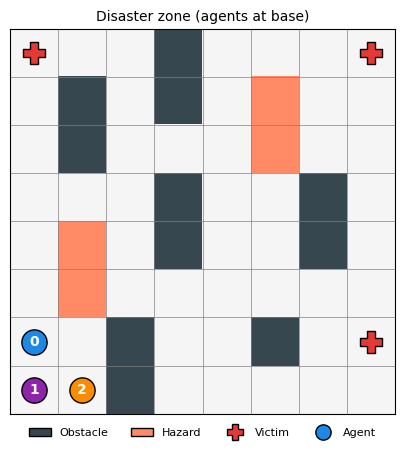

In [2]:
LAYOUT = [
    'V..#...V',
    '.#.#.H..',
    '.#...H..',
    '...#..#.',
    '.H.#..#.',
    '.H......',
    'A.#..#.V',
    'AA#.....',
]  # V victim | A agent start | # obstacle | H hazard | . free


class GridWorld:
    def __init__(self, layout):
        self.H, self.W = len(layout), len(layout[0])
        self.walls, self.hazards, self.victims, self.starts = set(), set(), [], []
        for y, row in enumerate(layout):
            for x, ch in enumerate(row):
                if ch == '#': self.walls.add((x, y))
                elif ch == 'H': self.hazards.add((x, y))
                elif ch == 'V': self.victims.append((x, y))
                elif ch == 'A': self.starts.append((x, y))
        self.n_agents, self.n_victims = len(self.starts), len(self.victims)
        self.victim_at = {v: i for i, v in enumerate(self.victims)}


LEGEND = [
    Patch(facecolor='#37474f', edgecolor='k', label='Obstacle'),
    Patch(facecolor='#ff8a65', edgecolor='k', label='Hazard'),
    Line2D([0], [0], marker='P', color='w', markerfacecolor='#e53935', markeredgecolor='k', markersize=11, label='Victim'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor=AGENT_COLORS[0], markeredgecolor='k', markersize=11, label='Agent'),
]


def draw_world(ax, env, positions=None, rescued=None, trails=None, title='', legend=False):
    ax.clear()
    grid = np.zeros((env.H, env.W))
    for x, y in env.walls: grid[y, x] = 1
    for x, y in env.hazards: grid[y, x] = 2
    ax.imshow(grid, cmap=ListedColormap(['#f5f5f5', '#37474f', '#ff8a65']), vmin=0, vmax=2)
    for v, (x, y) in enumerate(env.victims):
        saved = rescued is not None and rescued[v]
        ax.scatter(x, y, marker='P', s=260, c='#43a047' if saved else '#e53935', edgecolors='k', zorder=3)
    if trails:
        for i, tr in enumerate(trails):
            ax.plot([p[0] for p in tr], [p[1] for p in tr], color=AGENT_COLORS[i], lw=2.5, alpha=0.6, zorder=2)
    if positions:
        for i, (x, y) in enumerate(positions):
            ax.scatter(x, y, s=330, c=AGENT_COLORS[i], edgecolors='k', zorder=4)
            ax.text(x, y, str(i), color='w', ha='center', va='center', fontweight='bold', zorder=5)
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_xticks(np.arange(-0.5, env.W, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, env.H, 1), minor=True)
    ax.grid(which='minor', color='gray', lw=0.5)
    ax.tick_params(which='minor', length=0)
    ax.set_xlim(-0.5, env.W - 0.5); ax.set_ylim(env.H - 0.5, -0.5)
    ax.set_title(title, fontsize=10)
    if legend:
        ax.legend(handles=LEGEND, loc='upper center', bbox_to_anchor=(0.5, -0.01), ncol=4, frameon=False, fontsize=8)


world = GridWorld(LAYOUT)
fig, ax = plt.subplots(figsize=(5, 5))
draw_world(ax, world, positions=world.starts, title='Disaster zone (agents at base)', legend=True)
plt.show()

## 2. States, Actions & Rewards

**Actions:** up, down, left, right, stay

**State:** *independent* = own cell + victims still remaining; *cooperative* = own cell + assigned target victim

| Event | Reward |
|---|---|
| Rescue a victim | +50 |
| Move / stay | -1 / -0.5 |
| Hit wall or obstacle | -2 |
| Collision with another agent | -5 |
| Enter hazard cell | -10 |

In [3]:
ACTIONS = [(0, -1), (0, 1), (-1, 0), (1, 0), (0, 0)]   # up, down, left, right, stay
N_ACTIONS = len(ACTIONS)
R_RESCUE, R_MOVE, R_IDLE = 50, -1, -0.5
R_BUMP, R_COLLISION, R_HAZARD = -2, -5, -10


def manhattan(a, b):
    return abs(a[0] - b[0]) + abs(a[1] - b[1])


class RescueEnv(GridWorld):
    def __init__(self, layout, max_steps=T_MAX):
        super().__init__(layout)
        self.max_steps = max_steps

    def reset(self):
        self.pos = list(self.starts)
        self.rescued = [False] * self.n_victims
        self.t = self.collisions = self.hazard_hits = 0
        self.assign_targets()

    def assign_targets(self):
        # shared information: assign agents to remaining victims, minimising the longest distance
        rem = [v for v in range(self.n_victims) if not self.rescued[v]]
        self.targets = [self.n_victims] * self.n_agents      # value n_victims means no target
        k = min(len(rem), self.n_agents)
        if k == 0:
            return
        best = None
        for agents in itertools.combinations(range(self.n_agents), k):
            for vs in itertools.permutations(rem, k):
                d = [manhattan(self.pos[a], self.victims[v]) for a, v in zip(agents, vs)]
                key = (max(d), sum(d))
                if best is None or key < best[0]:
                    best = (key, agents, vs)
        for a, v in zip(best[1], best[2]):
            self.targets[a] = v

    def observe(self, i, shared_info):
        x, y = self.pos[i]
        cell = y * self.W + x
        if shared_info:                                    # own cell + assigned target
            return cell + self.targets[i] * self.W * self.H
        mask = sum(1 << v for v in range(self.n_victims) if not self.rescued[v])
        return cell + mask * self.W * self.H               # own cell + victims still remaining

    def n_states(self, shared_info):
        return self.W * self.H * ((self.n_victims + 1) if shared_info else 2 ** self.n_victims)

    def step(self, actions):
        n, cur = self.n_agents, self.pos
        self.t += 1
        rewards, intents = [0.0] * n, []
        for i, a in enumerate(actions):
            dx, dy = ACTIONS[a]
            x, y = cur[i]
            if (dx, dy) == (0, 0):
                rewards[i] += R_IDLE
                intents.append((x, y))
                continue
            rewards[i] += R_MOVE
            nx, ny = x + dx, y + dy
            if not (0 <= nx < self.W and 0 <= ny < self.H) or (nx, ny) in self.walls:
                rewards[i] += R_BUMP                        # hit wall / obstacle
                intents.append((x, y))
            else:
                intents.append((nx, ny))
        # resolve agent-agent conflicts: same target cell, swaps, moving into a blocked cell
        prio = random.sample(range(n), n)
        final, changed = list(intents), True
        while changed:
            changed = False
            for i in range(n):
                if final[i] == cur[i]:
                    continue
                for j in range(n):
                    if j == i:
                        continue
                    same = final[j] == final[i] and (final[j] == cur[j] or prio[j] < prio[i])
                    swap = final[i] == cur[j] and final[j] == cur[i]
                    if same or swap:
                        final[i] = cur[i]
                        rewards[i] += R_COLLISION
                        self.collisions += 1
                        changed = True
                        break
        self.pos, newly = final, False
        for i in range(n):
            p = final[i]
            if p != cur[i] and p in self.victim_at and not self.rescued[self.victim_at[p]]:
                self.rescued[self.victim_at[p]] = True
                rewards[i] += R_RESCUE
                newly = True
            if p in self.hazards:
                rewards[i] += R_HAZARD
                self.hazard_hits += 1
        done = all(self.rescued)
        if newly and not done:
            self.assign_targets()
        return rewards, done


env = RescueEnv(LAYOUT)

## 3. Independent Q-Learning
Each agent has its own Q-table and learns only from its own reward; teammates are treated as part of the environment. Progress is printed for seed 0.

In [4]:
def choose(q, eps):
    if random.random() < eps:
        return random.randrange(N_ACTIONS)
    best = np.flatnonzero(q == q.max())
    return int(best[0]) if len(best) == 1 else int(random.choice(best))


def run_episode(Q, cfg, eps, learn=True, record=False):
    env.reset()
    n, shared = env.n_agents, cfg['shared_info']
    qi = [0 if cfg['share_q'] else i for i in range(n)]    # which Q-table each agent uses
    obs = [env.observe(i, shared) for i in range(n)]
    total, done = 0.0, False
    frames = [(list(env.pos), list(env.rescued))] if record else None
    while not done and env.t < env.max_steps:
        acts = [choose(Q[qi[i], obs[i]], eps) for i in range(n)]
        rewards, done = env.step(acts)
        new_obs = [env.observe(i, shared) for i in range(n)]
        if learn:
            team = sum(rewards) / n
            for i in range(n):
                r = team if cfg['team_reward'] else rewards[i]
                nxt = 0.0 if done else GAMMA * Q[qi[i], new_obs[i]].max()
                Q[qi[i], obs[i], acts[i]] += ALPHA * (r + nxt - Q[qi[i], obs[i], acts[i]])
        obs = new_obs
        total += sum(rewards)
        if record:
            frames.append((list(env.pos), list(env.rescued)))
    out = dict(reward=total, rescued=sum(env.rescued), steps=env.t, collisions=env.collisions,
               hazards=env.hazard_hits, success=float(done))
    if record:
        out['frames'] = frames
    return out


def train_method(name):
    cfg = CONFIGS[name]
    RESULTS[name] = {'Q': [], 'hist': []}
    n_q = 1 if cfg['share_q'] else env.n_agents
    for seed in range(N_SEEDS):
        random.seed(seed); np.random.seed(seed)
        Q = np.zeros((n_q, env.n_states(cfg['shared_info']), N_ACTIONS))
        hist = {k: [] for k in ('reward', 'rescued', 'steps', 'collisions')}
        eps, t0 = EPS_START, time.time()
        for ep in range(N_EPISODES):
            m = run_episode(Q, cfg, eps)
            for k in hist:
                hist[k].append(m[k])
            eps = max(EPS_MIN, eps * EPS_DECAY)
            if seed == 0 and (ep + 1) % 500 == 0:
                r, c = np.mean(hist['reward'][-500:]), np.mean(hist['rescued'][-500:])
                print(f'  [{name}] ep {ep + 1:>4} | eps {eps:.2f} | reward {r:7.1f} | rescued {c:.2f}/{env.n_victims}')
        RESULTS[name]['Q'].append(Q)
        RESULTS[name]['hist'].append(hist)
        print(f'{name} | seed {seed} done in {time.time() - t0:.0f}s')


def smooth(x, w=50):
    return pd.Series(x).rolling(w, min_periods=1).mean().values


CURVES = [('reward', 'Cumulative team reward / episode'), ('rescued', 'Victims rescued / episode'),
          ('steps', 'Steps / episode'), ('collisions', 'Collisions / episode')]


def plot_curves(names):
    fig, axes = plt.subplots(2, 2, figsize=(12, 7))
    for ax, (key, label) in zip(axes.ravel(), CURVES):
        for name in names:
            runs = np.array([smooth(h[key]) for h in RESULTS[name]['hist']])
            m, s = runs.mean(0), runs.std(0)
            ax.plot(m, label=name, color=METHOD_COLORS[name], lw=2)
            ax.fill_between(np.arange(len(m)), m - s, m + s, color=METHOD_COLORS[name], alpha=0.15)
        ax.set_title(label); ax.set_xlabel('Episode'); ax.grid(alpha=0.3)
    axes[0, 0].legend()
    plt.tight_layout(); plt.show()

  [Independent] ep  500 | eps 0.37 | reward  -271.7 | rescued 2.50/3
  [Independent] ep 1000 | eps 0.14 | reward    38.0 | rescued 3.00/3
  [Independent] ep 1500 | eps 0.05 | reward    73.5 | rescued 3.00/3
  [Independent] ep 2000 | eps 0.02 | reward    90.0 | rescued 3.00/3
  [Independent] ep 2500 | eps 0.02 | reward    92.0 | rescued 3.00/3
  [Independent] ep 3000 | eps 0.02 | reward    93.9 | rescued 3.00/3
Independent | seed 0 done in 2s
Independent | seed 1 done in 2s
Independent | seed 2 done in 2s


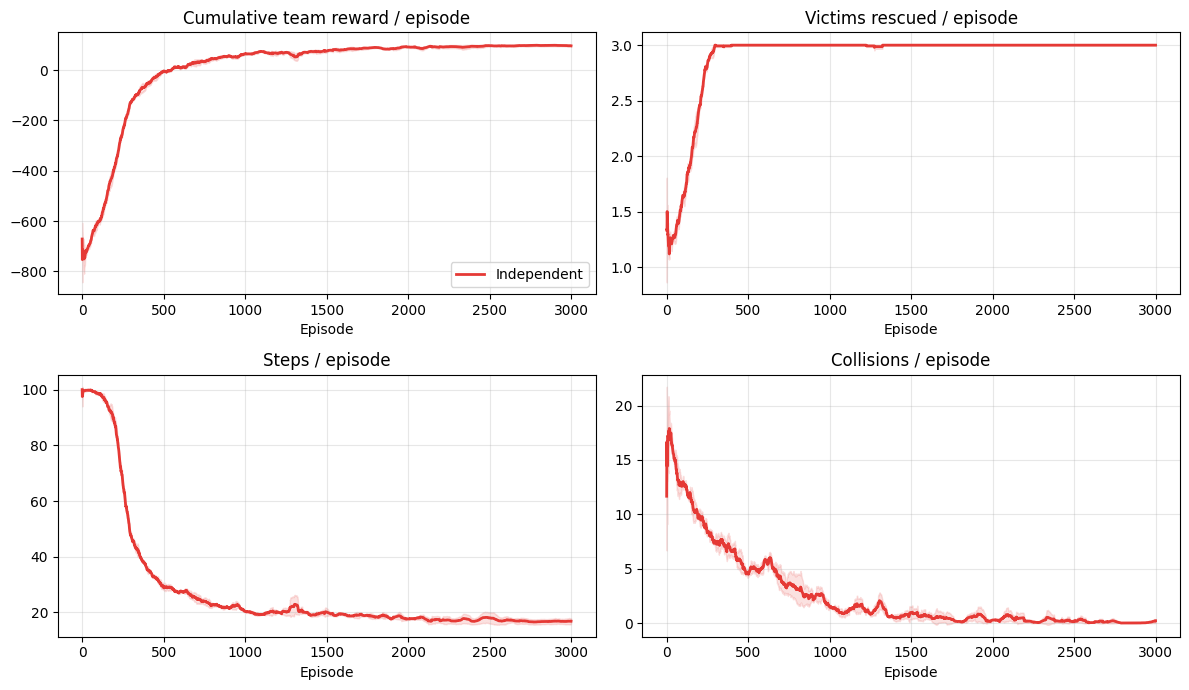

In [5]:
CONFIGS = {'Independent': dict(team_reward=False, shared_info=False, share_q=False)}
RESULTS = {}

train_method('Independent')
plot_curves(['Independent'])

## 4. Cooperative Learning
Two coordination mechanisms are compared with independent learning:
- **Common reward:** every agent learns from the team's mean reward.
- **Shared information:** agents broadcast their positions, a min-max-distance rule assigns each a target victim, and all agents share one Q-table.

*Team-reward only* uses the first mechanism; *Cooperative* uses both.

In [6]:
CONFIGS['Team-reward only'] = dict(team_reward=True, shared_info=False, share_q=False)
CONFIGS['Cooperative'] = dict(team_reward=True, shared_info=True, share_q=True)

train_method('Team-reward only')
train_method('Cooperative')

  [Team-reward only] ep  500 | eps 0.37 | reward  -280.3 | rescued 2.51/3
  [Team-reward only] ep 1000 | eps 0.14 | reward    35.0 | rescued 3.00/3
  [Team-reward only] ep 1500 | eps 0.05 | reward    70.6 | rescued 3.00/3
  [Team-reward only] ep 2000 | eps 0.02 | reward    83.4 | rescued 3.00/3
  [Team-reward only] ep 2500 | eps 0.02 | reward    82.5 | rescued 3.00/3
  [Team-reward only] ep 3000 | eps 0.02 | reward    85.3 | rescued 3.00/3
Team-reward only | seed 0 done in 2s
Team-reward only | seed 1 done in 2s
Team-reward only | seed 2 done in 2s
  [Cooperative] ep  500 | eps 0.37 | reward  -243.9 | rescued 2.63/3
  [Cooperative] ep 1000 | eps 0.14 | reward    25.9 | rescued 2.99/3
  [Cooperative] ep 1500 | eps 0.05 | reward    60.2 | rescued 2.99/3
  [Cooperative] ep 2000 | eps 0.02 | reward    75.5 | rescued 2.99/3
  [Cooperative] ep 2500 | eps 0.02 | reward    67.2 | rescued 2.99/3
  [Cooperative] ep 3000 | eps 0.02 | reward    74.4 | rescued 3.00/3
Cooperative | seed 0 done in 2s

## 5. Visualization
Learning curves (50-episode moving average, mean ± std over seeds), final trajectories, rescue progress and step-by-step animations.

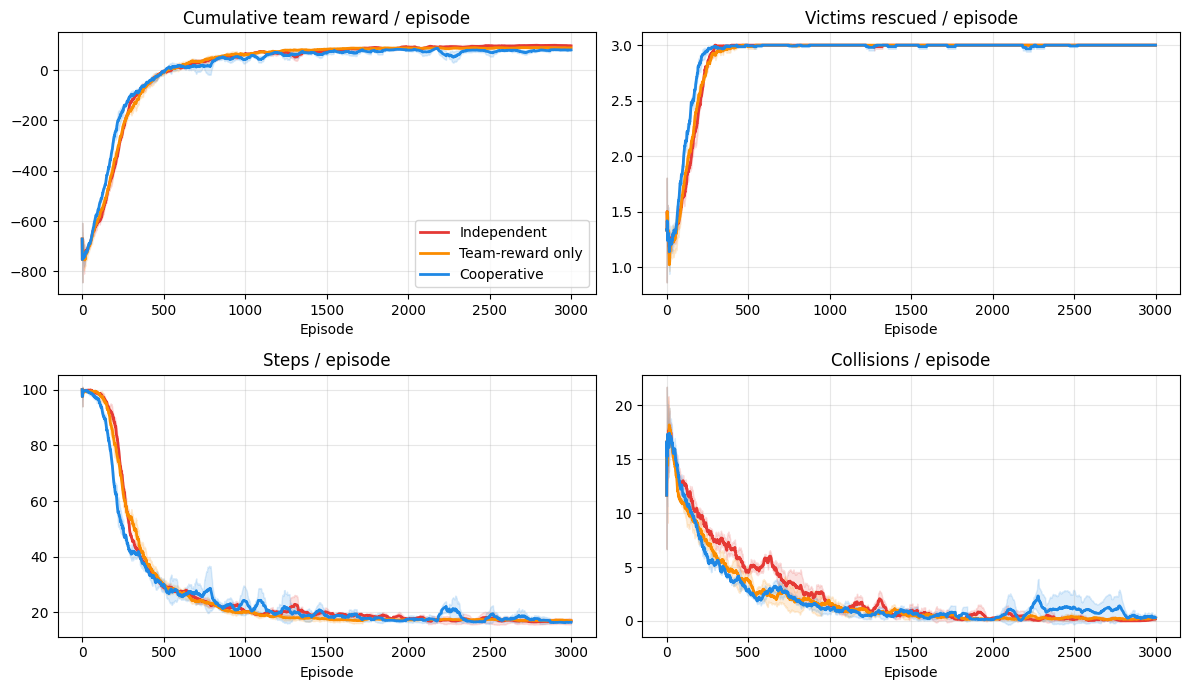

In [7]:
plot_curves(list(CONFIGS))

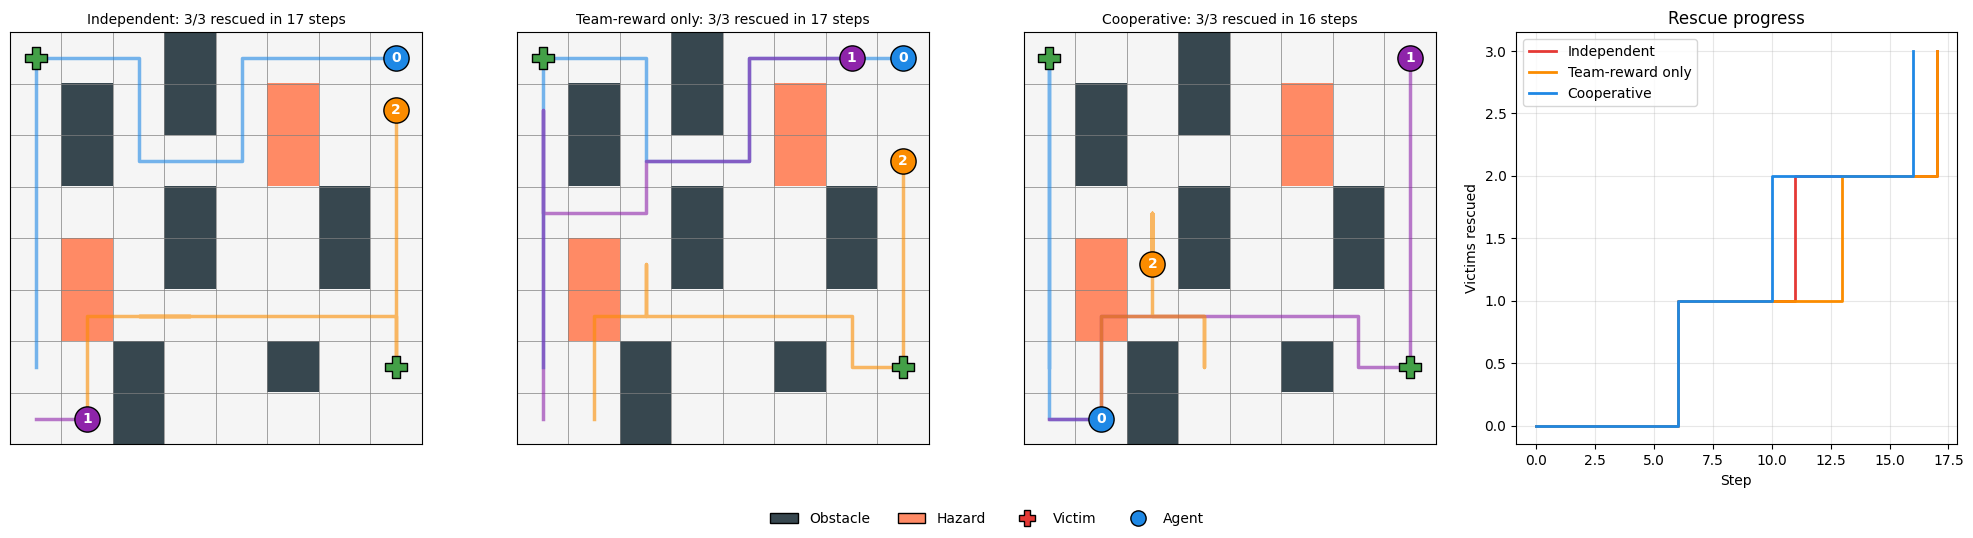

In [8]:
def rollout(name, seed=0):
    random.seed(123)
    return run_episode(RESULTS[name]['Q'][seed], CONFIGS[name], eps=0.0, learn=False, record=True)


ROLLOUTS = {n: rollout(n) for n in CONFIGS}

fig, axes = plt.subplots(1, 4, figsize=(20, 5.4))
for ax, n in zip(axes[:3], CONFIGS):
    r = ROLLOUTS[n]
    fr = r['frames']
    trails = [[f[0][i] for f in fr] for i in range(env.n_agents)]
    title = '%s: %d/%d rescued in %d steps' % (n, r['rescued'], env.n_victims, r['steps'])
    draw_world(ax, env, fr[-1][0], fr[-1][1], trails, title)

for n in CONFIGS:
    prog = [sum(f[1]) for f in ROLLOUTS[n]['frames']]
    axes[3].step(range(len(prog)), prog, where='post', label=n, color=METHOD_COLORS[n], lw=2)
axes[3].set_xlabel('Step'); axes[3].set_ylabel('Victims rescued'); axes[3].set_title('Rescue progress')
axes[3].legend(); axes[3].grid(alpha=0.3)

fig.legend(handles=LEGEND, loc='lower center', ncol=4, frameon=False)
plt.tight_layout(rect=[0, 0.06, 1, 1])
plt.show()

In [9]:
def animate(res, title):
    fig, ax = plt.subplots(figsize=(4.5, 4.5))
    frames = res['frames']

    def update(k):
        pos, resc = frames[k]
        trails = [[f[0][i] for f in frames[:k + 1]] for i in range(env.n_agents)]
        draw_world(ax, env, pos, resc, trails, title + ' | step ' + str(k))

    anim = FuncAnimation(fig, update, frames=len(frames), interval=500)
    plt.close(fig)
    return HTML(anim.to_jshtml())


display(animate(ROLLOUTS['Independent'], 'Independent'))
display(animate(ROLLOUTS['Cooperative'], 'Cooperative'))

## 6. Performance Evaluation
Greedy policies (ε = 0), 100 episodes per seed, mean ± std over seeds. Failed episodes count as the step limit.

In [10]:
LABELS = {'success': 'Success rate', 'rescued': 'Victims rescued (of 3)', 'steps': 'Completion time (steps)',
          'reward': 'Cumulative reward', 'collisions': 'Collisions', 'hazards': 'Hazard hits'}


def evaluate(name):
    cfg, rows = CONFIGS[name], []
    for seed, Q in enumerate(RESULTS[name]['Q']):
        random.seed(1000 + seed)
        runs = [run_episode(Q, cfg, eps=0.0, learn=False) for _ in range(EVAL_EPISODES)]
        rows.append({k: np.mean([e[k] for e in runs]) for k in LABELS})
    return pd.DataFrame(rows)


EVAL = {name: evaluate(name) for name in CONFIGS}
summary = pd.DataFrame({n: d.mean() for n, d in EVAL.items()}).T
std = pd.DataFrame({n: d.std(ddof=0) for n, d in EVAL.items()}).T
table = pd.DataFrame({LABELS[k]: [f'{summary.loc[n, k]:.2f} ± {std.loc[n, k]:.2f}' for n in summary.index]
                      for k in LABELS}, index=summary.index)
display(table)

,Success rate,Victims rescued (of 3),Completion time (steps),Cumulative reward,Collisions,Hazard hits
Independent,1.00 ± 0.00,3.00 ± 0.00,16.33 ± 0.94,99.83 ± 3.70,0.00 ± 0.00,1.00 ± 0.00
Team-reward only,1.00 ± 0.00,3.00 ± 0.00,16.67 ± 0.47,91.50 ± 4.64,0.00 ± 0.00,1.00 ± 0.00
Cooperative,1.00 ± 0.00,3.00 ± 0.00,16.00 ± 0.00,84.67 ± 1.43,0.00 ± 0.00,2.00 ± 0.00


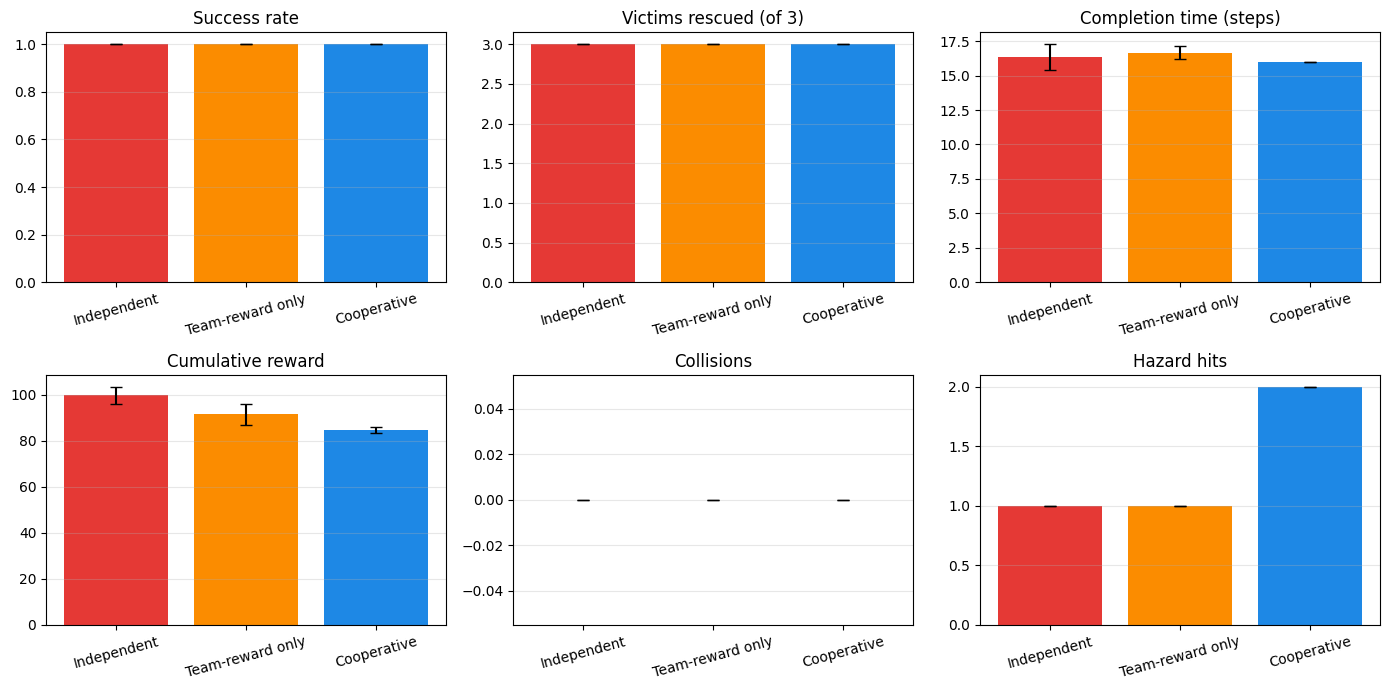

Best Success rate              : Independent
Best Victims rescued (of 3)    : Independent
Best Completion time (steps)   : Cooperative
Best Cumulative reward         : Independent
Best Collisions                : Independent
Best Hazard hits               : Independent


In [11]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
names = list(summary.index)
for ax, (k, label) in zip(axes.ravel(), LABELS.items()):
    ax.bar(names, summary[k], yerr=std[k], capsize=4, color=[METHOD_COLORS[n] for n in names])
    ax.set_title(label); ax.tick_params(axis='x', rotation=15); ax.grid(axis='y', alpha=0.3)
plt.tight_layout(); plt.show()

lower_is_better = {'steps', 'collisions', 'hazards'}
for k, label in LABELS.items():
    best = summary[k].idxmin() if k in lower_is_better else summary[k].idxmax()
    print(f'Best {label:<26}: {best}')